# Лабораторна робота № 3
## Діагностика шкал вимірювання

Курс СК26 «Інтелектуальний аналіз та візуалізація даних»

**Тривалість:** 2 год аудиторно + 3 год самостійно · **Оцінка:** 4 бали
**Файли:** `Ковід_дані_навчальні.xlsx`, `ЛР3_помилковий_аналіз.ipynb`

---

Шкала вимірювання визначає, які операції над змінною взагалі мають сенс.
Комп'ютер цього не знає: він порахує середнє від номера телефону й не поскаржиться.
Знати має вимірювач.

У цій роботі ви складаєте **паспорт восьми змінних** свого варіанта, показуєте на
власних даних, які статистики для них недопустимі, і виправляєте чужий аналіз,
де таких помилок десять.

In [430]:
ПРІЗВИЩЕ_ІМЯ = 'Паничевська Ярина Ернестівна'      # напишіть тут своє прізвище та ім'я
ГРУПА        = 'ШІ-32'
НОМЕР        = 15      # ваш номер за списком групи (1–30)

assert ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР, 'Заповніть три поля вище'
assert 1 <= НОМЕР <= 30, 'Номер має бути від 1 до 30'

In [431]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 60)

ВАРІАНТИ = json.load(open('lr3_variants_student.json', 'r', encoding='utf-8'))
В = ВАРІАНТИ[НОМЕР - 1]

print('=' * 74)
print(f'ВАРІАНТ {В["варіант"]}   ·   {ПРІЗВИЩЕ_ІМЯ}   ·   {ГРУПА}')
print('=' * 74)
print()
print('Ваші вісім стовпців:')
for i, c in enumerate(В['стовпці'], 1):
    print(f'   {i}. {c}')
print()
print('Ваша пара для аналізу зв’язку:', ' та '.join(В['пара']))
print()
print('Ваше додаткове питання:')
print('  ', В['питання'])

ВАРІАНТ 15   ·   Паничевська Ярина Ернестівна   ·   ШІ-32

Ваші вісім стовпців:
   1. Телефон
   2. Стать
   3. ступінь КТ
   4. Виписка
   5. КТ
   6. Т вище 37,5
   7. Сечов2
   8. БРпр1

Ваша пара для аналізу зв’язку: Стать та ступінь КТ

Ваше додаткове питання:
   Чому не можна обчислити коефіцієнт кореляції Пірсона між статтю та результатом лікування? Яку міру зв’язку слід узяти замість нього?


In [432]:
ФАЙЛ = 'Ковід_дані_навчальні.xlsx'
df = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')
МОЇ = В['стовпці']

print('Розмір набору:', df.shape)
df[МОЇ].head(8)

Розмір набору: (121, 77)


,Телефон,Стать,ступінь КТ,Виписка,КТ,"Т вище 37,5",Сечов2,БРпр1
0,0958469788 дружина Ганна,ч,сердній,2022-03-10 00:00:00,20-30%,3,6.5,3.4
1,"0671778486, 0994887663 дружина Оксана",ч,середній,2022-03-16 00:00:00,30-35%,3,4,2.8
2,"0958768045, чоловік Степан 0951784726",ж,критичний,2022-01-18 00:00:00,70-80%,3,10.1,2.8
3,0959819331. дочка Валентина 0960845205,ж,критичний,2022-01-13 00:00:00,0.8,6,12.5,3.4
4,"0952294866, дочка Дарина 0678360161",ж,NaN,2022-03-11 00:00:00,NaN,5 до гос,7.4,3.4
5,0959922983 сестра Софія,ж,середній,2021-12-26 00:00:00,30-40%,NaN,21.4,3.4
6,"0998073702, дружина Наталія 0998382226",ч,важкий,2022-05-11 00:00:00,60-65%,NaN,6.1,5.1
7,"0637258771, син Сергій 0968413301",ж,легкий,2022-05-28 00:00:00,до 17%,NaN,7.6,5.1


---
# Етап 1. Паспорт змінних

Для кожного з восьми стовпців визначте шкалу вимірювання. Спирайтеся не на тип даних
у pandas, а на **зміст величини**: що означають її значення і які порівняння між ними
мають сенс.

Нагадування:

| Шкала | Ознака |
|---|---|
| Номінальна | значення можна лише порівняти на рівність |
| Порядкова | є природний порядок, але відстані між сусідніми рівнями невідомі |
| Інтервальна | різниці мають сенс, нуль умовний |
| Відношень | є природний нуль, відношення мають сенс |
| Абсолютна | природні і нуль, і одиниця вимірювання |

Окремо позначайте **ідентифікатори** — значення, що не є величиною взагалі
(номер історії хвороби, прізвище, телефон).

In [433]:
# Спершу подивіться, що каже pandas — і не довіряйте йому
df[МОЇ].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Телефон      120 non-null    object 
 1   Стать        121 non-null    object 
 2   ступінь КТ   42 non-null     object 
 3   Виписка      120 non-null    object 
 4   КТ           44 non-null     object 
 5   Т вище 37,5  78 non-null     object 
 6   Сечов2       102 non-null    object 
 7   БРпр1        109 non-null    float64
dtypes: float64(1), object(7)
memory usage: 7.7+ KB


In [434]:
# Далі — що є всередині насправді
for c in МОЇ:
    з = df[c].dropna()
    типи = ', '.join(f'{t.__name__}×{n}' for t, n in з.map(type).value_counts().items())
    print(f'--- {c}')
    print(f'    непорожніх {len(з)} з {len(df)} | унікальних {з.nunique()} | типи: {типи}')
    print(f'    приклади: {[repr(v) for v in з.unique()[:4]]}')
    print()

--- Телефон
    непорожніх 120 з 121 | унікальних 120 | типи: str×97, int×23
    приклади: ["'0958469788 дружина Ганна'", "'0671778486, 0994887663 дружина Оксана'", "'0958768045, чоловік Степан 0951784726'", "'0959819331. дочка Валентина 0960845205'"]

--- Стать
    непорожніх 121 з 121 | унікальних 4 | типи: str×121
    приклади: ["'ч'", "'ж'", "'чол'", "'жін'"]

--- ступінь КТ
    непорожніх 42 з 121 | унікальних 12 | типи: str×42
    приклади: ["'сердній'", "'середній'", "'критичний'", "'важкий'"]

--- Виписка
    непорожніх 120 з 121 | унікальних 90 | типи: datetime×118, str×2
    приклади: ['datetime.datetime(2022, 3, 10, 0, 0)', 'datetime.datetime(2022, 3, 16, 0, 0)', 'datetime.datetime(2022, 1, 18, 0, 0)', 'datetime.datetime(2022, 1, 13, 0, 0)']

--- КТ
    непорожніх 44 з 121 | унікальних 26 | типи: float×27, str×17
    приклади: ["'20-30%'", "'30-35%'", "'70-80%'", '0.8']

--- Т вище 37,5
    непорожніх 78 з 121 | унікальних 35 | типи: str×48, int×30
    приклади: ['3', '6', "

### Заповніть паспорт

Для кожного стовпця вкажіть шкалу та **обґрунтування** — одне речення про те,
чому саме ця шкала. Обґрунтування оцінюється, назва шкали сама по собі — ні.

In [435]:
ПАСПОРТ = {
    'Телефон': ('Ідентифікатор', 'Номер телефону (часто разом з іменем родича) лише вказує на конкретну людину'),
    'Стать': ('Номінальна', 'Дві категорії (ч/ж) без природного порядку: значення можна лише порівняти на рівність'),
    'ступінь КТ': ('Порядкова', 'Рівні легкий < середній < важкий < вкрай важкий < критичний упорядковані за тяжкістю, але відстань між сусідніми рівнями невідома й не обов’язково однакова'),
    'Виписка': ('Інтервальна', 'Дата виписки: різниця двох дат (кількість днів) має сенс, а нуль календаря умовний'),
    'КТ': ('Відношень', 'Відсоток ураження легеневої тканини: 0 % означає відсутність ураження (природний нуль)'),
    'Т вище 37,5': ('Абсолютна', 'Кількість днів із температурою понад 37,5 °C — це лічба: природний нуль (жодного дня) і природна одиниця (один день), значення лише цілі'),
    'Сечов2': ('Відношень', 'Концентрація сечовини у повторному аналізі: нуль означає відсутність речовини'),
    'БРпр1': ('Відношень', 'Прямий білірубін у першому аналізі: природний нуль концентрації, відношення '),
}

for c in МОЇ:
    ПАСПОРТ.setdefault(c, ('', ''))

паспорт_df = pd.DataFrame(
    [(c, ПАСПОРТ[c][0], ПАСПОРТ[c][1]) for c in МОЇ],
    columns=['Стовпець', 'Шкала', 'Обґрунтування'])
паспорт_df

,Стовпець,Шкала,Обґрунтування
0,Телефон,Ідентифікатор,Номер телефону (часто разом з іменем родича) лише вказує...
1,Стать,Номінальна,Дві категорії (ч/ж) без природного порядку: значення мож...
2,ступінь КТ,Порядкова,Рівні легкий < середній < важкий < вкрай важкий < критич...
3,Виписка,Інтервальна,Дата виписки: різниця двох дат (кількість днів) має сенс...
4,КТ,Відношень,Відсоток ураження легеневої тканини: 0 % означає відсутн...
5,"Т вище 37,5",Абсолютна,"Кількість днів із температурою понад 37,5 °C — це лічба:..."
6,Сечов2,Відношень,Концентрація сечовини у повторному аналізі: нуль означає...
7,БРпр1,Відношень,Прямий білірубін у першому аналізі: природний нуль конце...


In [436]:
# --- САМОПЕРЕВІРКА 1 ---
ДОПУСТИМІ = {'номінальна', 'порядкова', 'інтервальна', 'відношень',
             'абсолютна', 'ідентифікатор'}
for c in МОЇ:
    ш, об = ПАСПОРТ[c]
    assert ш.strip().lower() in ДОПУСТИМІ, f'{c}: шкалу «{ш}» не розпізнано'
    assert len(об.strip()) >= 25, f'{c}: обґрунтування закоротке'
print('Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.')

Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.


---
# Етап 2. Допустимі статистики

Для кожного стовпця обчисліть **тільки те, що дозволяє його шкала**.

* номінальна та ідентифікатор — мода, частоти
* порядкова — додатково медіана та квантилі
* інтервальна — додатково середнє та стандартне відхилення
* відношень і абсолютна — усе, зокрема коефіцієнт варіації

Якщо для стовпця не можна порахувати нічого, крім частот, — так і напишіть.

In [437]:
import re

РІВНІ_КТ = ['легкий', 'середній', 'важкий', 'вкрай важкий', 'критичний']


def числа(x):
    """дістаємо числа з тексту"""
    return [float(n) for n in re.findall(r'\d+\.?\d*', str(x))]


def стать(x):
    x = x.strip()
    if x.startswith('чол'): return 'ч'
    elif x.startswith('жін'): return 'ж'
    return x


def ступінь(x):
    if pd.isna(x):
        return None
    x = x.strip()                                   
    if x.startswith('сер'): return 'середній'
    if x == 'легка': return 'легкий'
    return x


def кт(x):
    if isinstance(x, float):                        
        return x * 100
    ч = числа(x)  
    #якщо у нас діапазон, то беремо середнє                                 
    return np.mean(ч) if ч else None


def дні(x):
    if isinstance(x, int):                         
        return x
    ч = числа(x)
    # для випадку, якщо у тексті написано щось на кшталт: 5 днів до госп+3 дні в стац                               
    return sum(ч) if ч else None


def clean_data(df):
    чисті_дані = df.copy()
    чисті_дані['Телефон'] = df['Телефон']
    чисті_дані['Стать'] = df['Стать'].apply(стать)
    чисті_дані['ступінь КТ'] = pd.Categorical(df['ступінь КТ'].apply(ступінь), categories=РІВНІ_КТ, ordered=True)
    чисті_дані['Виписка'] = pd.to_datetime(df['Виписка'], errors='coerce')   
    чисті_дані['КТ'] = df['КТ'].apply(кт)
    чисті_дані['Т вище 37,5'] = df['Т вище 37,5'].apply(дні)
    чисті_дані['Сечов2'] = pd.to_numeric(df['Сечов2'], errors='coerce')     
    чисті_дані['БРпр1'] = df['БРпр1']                                      
    return чисті_дані

df = clean_data(df)

In [438]:
def допустима_статистика(стовпець, шкала):
    """Повертає словник статистик, дозволених для цієї шкали."""
    з = df[стовпець].dropna()
    р = {'непорожніх': len(з), 'унікальних': з.nunique()}
    ш = шкала.strip().lower()

    if ш in ('ідентифікатор',):
        return р
    
    #для всіх шкал вимірювань
    р['мода'] = з.mode()[0]
    р['частоти'] = з.value_counts().to_dict()

    if ш == 'номінальна':
        return р

    if ш == 'порядкова':
        коди = з.astype(str).map(РІВНІ_КТ.index)  
        р['Q1'] = РІВНІ_КТ[int(коди.quantile(0.25, interpolation='lower'))]
        р['Q2 (медіана)'] = РІВНІ_КТ[int(коди.quantile(0.50, interpolation='lower'))]
        р['Q3'] = РІВНІ_КТ[int(коди.quantile(0.75, interpolation='lower'))]
        return р

    #для шкали інтервальна і вище
    р['середнє'] = з.mean()
    р['ст. відхилення'] = з.std()
    р['Q1'] = з.quantile(0.25)
    р['Q2 (медіана)'] = з.median()
    р['Q3'] = з.quantile(0.75)

    if ш in ('відношень', 'абсолютна'):
        р['CV'] = з.std() / з.mean() * 100
    return р

In [439]:
def гарно(значення):
    if isinstance(значення, pd.Timestamp):
        return значення.strftime('%d.%m.%Y')
    if isinstance(значення, pd.Timedelta):
        return f'{значення.days} днів'
    if isinstance(значення, float):
        return str(round(значення, 2))
    return str(значення)


for c in МОЇ:
    шкала = ПАСПОРТ[c][0]
    р = допустима_статистика(c, шкала)
    print(f'Колонка: {c}  Шкала вимірювання: {шкала}')
    for назва, значення in р.items():
        if назва == 'частоти':
            топ = list(значення.items())[:5]
            текст = ', '.join(f'{гарно(k)}: {v}' for k, v in топ)
            if len(значення) > 5:
                текст += f'  … ще {len(значення) - 5}'
            print(f' {"частоти":<16}{текст}')
        else:
            print(f' {назва:<16}{гарно(значення)}')
    print()

Колонка: Телефон  Шкала вимірювання: Ідентифікатор
 непорожніх      120
 унікальних      120

Колонка: Стать  Шкала вимірювання: Номінальна
 непорожніх      121
 унікальних      2
 мода            ж
 частоти         ж: 75, ч: 46

Колонка: ступінь КТ  Шкала вимірювання: Порядкова
 непорожніх      42
 унікальних      5
 мода            середній
 частоти         середній: 18, важкий: 10, легкий: 7, вкрай важкий: 4, критичний: 3
 Q1              середній
 Q2 (медіана)    середній
 Q3              важкий

Колонка: Виписка  Шкала вимірювання: Інтервальна
 непорожніх      118
 унікальних      88
 мода            07.09.2021
 частоти         07.09.2021: 3, 06.06.2022: 3, 06.04.2022: 3, 19.11.2021: 3, 11.09.2021: 3  … ще 83
 середнє         29.01.2022
 ст. відхилення  109 днів
 Q1              16.11.2021
 Q2 (медіана)    15.03.2022
 Q3              27.04.2022

Колонка: КТ  Шкала вимірювання: Відношень
 непорожніх      43
 унікальних      21
 мода            30.0
 частоти         30.0: 7, 25.0: 6

---
# Етап 3. Три безглузді числа

`df.describe()` порахує статистики для всього, що схоже на число. Частина цих чисел
не має жодного змісту.

Знайдіть **щонайменше три** такі числа у своєму наборі: обчисліть їх, а потім
поясніть, чому кожне з них безглузде.

In [440]:
df[МОЇ].describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Телефон,120,120,0958469788 дружина Ганна,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Стать,121,2,ж,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ступінь КТ,42,5,середній,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Виписка,118,NaN,NaN,NaN,2022-01-29 18:06:06.101694976,2021-04-27 00:00:00,2021-11-16 18:00:00,2022-03-15 00:00:00,2022-04-27 18:00:00,2022-06-22 00:00:00,NaN
КТ,43.0,NaN,NaN,NaN,42.5,5.0,26.25,35.0,63.75,80.0,21.966154
"Т вище 37,5",78.0,NaN,NaN,NaN,4.217949,1.0,3.0,3.0,5.0,14.0,2.399391
Сечов2,101.0,NaN,NaN,NaN,10.198614,3.4,5.9,7.3,10.0,116.0,13.274622
БРпр1,109.0,NaN,NaN,NaN,4.801468,2.4,3.4,5.1,5.3,10.2,1.575191


In [441]:
стать_1 = df['Стать'].map({'ч': 0, 'ж': 1}).mean()
стать_2 = df['Стать'].map({'ч': 1, 'ж': 0}).mean()

ступінь = df['ступінь КТ'].dropna().astype(str).map(РІВНІ_КТ.index) + 1
сер_ступінь = ступінь.mean()

вип = df['Виписка'].dropna()
дні_1970 = (вип - pd.Timestamp('1970-01-01')).dt.days
дні_2021 = (вип - pd.Timestamp('2021-01-01')).dt.days
cv_1970 = дні_1970.std() / дні_1970.mean() * 100
cv_2021 = дні_2021.std() / дні_2021.mean() * 100

БЕЗГЛУЗДІ = [
    ('Телефон', 'top і freq', 'top = 0958469788 дружина Ганна, freq = 1', 'Мода ідентифікатор загалом безглузда'),

    ('ступінь КТ', 'середнє рангів 1–5 (1-лекий, 2-середній і тд)', f'{сер_ступінь:.2f}',
     'Ступінь «2,48» не існує серед ступенів КТ'),

    ('Стать', 'середнє кодів', f'{стать_1:.2f} (ч=0, ж=1) або {стать_2:.2f} (ч=1, ж=0)', 'Коди 0 і 1 обрано довільно: поміняли місцями — отримали інше «середнє». Для номінальної шкали середнього не існує, є лише частоти й мода'),
          
    ('Виписка', 'коефіцієнт варіації', f'{cv_1970:.2f} % (від 1970) або {cv_2021:.1f} % (від 2021)',
     'Коефіцієнт варіації ділить розкид на середнє. Для дат середнє залежить від того, з якого дня ми почали відлік, тому CV для тих самих дат може бути різним. Також CV потребує природного нуля, а нуль календаря умовний'),
]

assert len(БЕЗГЛУЗДІ) >= 3, 'Потрібно щонайменше три приклади'
pd.DataFrame(БЕЗГЛУЗДІ, columns=['Стовпець', 'Статистика', 'Значення', 'Чому безглузде'])

,Стовпець,Статистика,Значення,Чому безглузде
0,Телефон,top і freq,"top = 0958469788 дружина Ганна, freq = 1",Мода ідентифікатор загалом безглузда
1,ступінь КТ,"середнє рангів 1–5 (1-лекий, 2-середній і тд)",2.48,"Ступінь «2,48» не існує серед ступенів КТ"
2,Стать,середнє кодів,"0.62 (ч=0, ж=1) або 0.38 (ч=1, ж=0)",Коди 0 і 1 обрано довільно: поміняли місцями — отримали ...
3,Виписка,коефіцієнт варіації,0.58 % (від 1970) або 27.8 % (від 2021),Коефіцієнт варіації ділить розкид на середнє. Для дат се...


---
# Етап 4. Міра зв'язку для вашої пари

Для двох змінних вашого варіанта треба оцінити зв'язок. Міру обирає **пара шкал**,
а не зручність:

| Поєднання шкал | Міра |
|---|---|
| відношень × відношень | кореляція Пірсона |
| порядкова × порядкова | рангова кореляція Спірмена |
| номінальна × номінальна | χ² та коефіцієнт Крамера (V) |
| відношень × бінарна номінальна | точковий бісеріальний коефіцієнт |
| номінальна × порядкова | коефіцієнт Крамера (V) |

Обґрунтуйте вибір, обчисліть міру й поясніть результат. Окремо покажіть, **що
станеться**, якщо застосувати Пірсона там, де він недопустимий, — і чому отримане
число не можна інтерпретувати.

In [442]:
A, B = В['пара']
print('Ваша пара:', A, '×', B)
print()
print(f'{A}: шкала —', ПАСПОРТ.get(A, ('не у вашому списку',))[0] or '(визначте самостійно)')
print(f'{B}: шкала —', ПАСПОРТ.get(B, ('не у вашому списку',))[0] or '(визначте самостійно)')
print()
print(df[[A, B]].head(6).to_string())

Ваша пара: Стать × ступінь КТ

Стать: шкала — Номінальна
ступінь КТ: шкала — Порядкова

  Стать ступінь КТ
0     ч   середній
1     ч   середній
2     ж  критичний
3     ж  критичний
4     ж        NaN
5     ж   середній


In [443]:
ОБРАНА_МІРА = 'Коефіцієнт крамера (V)'
ЧОМУ_САМЕ_ВОНА = "У мене для колонки стать - номінальна шкала, для колонки ступінь КТ - порядкова. Коеціфієнт крамера використовується для оцінки сили зв'язку між двома номінальними змінними, проте можна і між номінальною та порядковою, якщо розглядати порядкову шкалу як номінальну (тобто проігнорувати інформацію про порядок)"

assert ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40, 'Заповніть обидва поля'


In [444]:
from scipy.stats import chi2_contingency

def критерій_крамера(df):
    chi2, p, dof, очік = chi2_contingency(df, correction=False)

    n = df.to_numpy().sum()
    V = np.sqrt(chi2 / (n * (min(df.shape) - 1)))
    return chi2, p, dof, V, очік

In [445]:
#беремо лише пацієнтів, у яких непусті ці дві колонки
табл = pd.crosstab(df['Стать'], df['ступінь КТ'])
табл

ступінь КТ,легкий,середній,важкий,вкрай важкий,критичний
Стать,,,,,
ж,4,8,4,2,3
ч,3,10,6,2,0


In [446]:
chi2, p, dof, V, очік = критерій_крамера(табл)

print('Очікувана таблиця (якби зв\'язку не було):')
print(pd.DataFrame(очік, index=табл.index, columns=табл.columns).round(1))
print()
print(f'Пацієнтів у таблиці: {табл.to_numpy().sum()}')
print(f'χ² = {chi2:.2f}')
print(f'p = {p:.3f}')
print(f'V Крамера = {V:.2f}')

Очікувана таблиця (якби зв'язку не було):
ступінь КТ  легкий  середній  важкий  вкрай важкий  критичний
Стать                                                        
ж              3.5       9.0     5.0           2.0        1.5
ч              3.5       9.0     5.0           2.0        1.5

Пацієнтів у таблиці: 42
χ² = 3.77
p = 0.439
V Крамера = 0.30


**Нотатки:**

p - дає відповідь на питання: "якби між нашими двома ознаками взагалі не було зв'язку, яка ймовірність отримати такі ж  результати чисто випадково?". 
- Якщо p <= 0.05 - результат вважають статистично значущим (зв'язок є, це не випадковість)
- Якщо p > 0.05 - результат вважають незначущим (зв'язок не доведений, це може бути випадковий збіг)

у нас значення p = 0.439, зв'язок не є доведеним.

V Крамера = 0.3. За таблицею Коена, це вказує на те, що зв'язок між двома колонками є середнім:

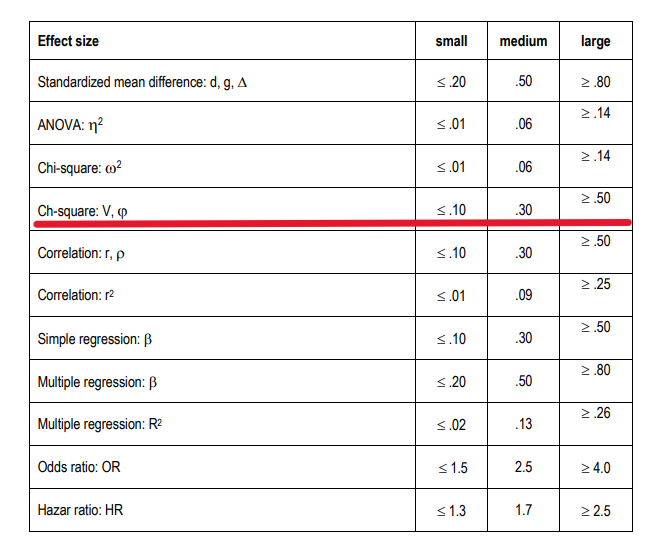

In [447]:
from scipy.stats import pearsonr

пара = df[['Стать', 'ступінь КТ']].dropna()
ступінь = пара['ступінь КТ'].astype(str).map(РІВНІ_КТ.index)

r1, p1 = pearsonr(пара['Стать'].map({'ж': 0, 'ч': 1}), ступінь)
r2, p2 = pearsonr(пара['Стать'].map({'ж': 1, 'ч': 0}), ступінь)

print("Кодування статті (ч=1, ж=0)")
print(f"r (корел. Пірсона) = {r1:.2f}, p = {p1:.2f}\n")
print("Кодування статті (ч=0, ж=1)")
print(f"r (корел. Пірсона) = {r2:.2f}, p = {p2:.2f}")

Кодування статті (ч=1, ж=0)
r (корел. Пірсона) = -0.13, p = 0.41

Кодування статті (ч=0, ж=1)
r (корел. Пірсона) = 0.13, p = 0.41


**Висновок:**
Ми закодовували статті по різному і отримали різний коефіцієнт кореляції (r1, r2).

У першому випадку r1 = -0.13 , у другому r2 = +0.13. 

Загалом знак кореляції вказує на те як змінюються одне відносно одного ознаки:
- Позитивна кореляція (r > 0): Змінні рухаються в одному напрямку. Якщо росте одна, росте й інша.
- Негативна  кореляція (r < 0): Змінні рухаються в протилежних напрямках. Якщо одна росте, інша зменшується.
- Відсутність зв'язку (r = 0): Зміни однієї змінної ніяк не пов'язані зі змінами іншої.

У нас змінна "Стать" - номінальна шкала. "ж" не може бути більшою чи меншою за "ч". Як бачимо, закодувавши по-різному ці статті маємо різні результати. Це безглуздо. Тому кореляцію Пірсона тут не доречно застосовувати.

В обох випадках p = 0.41 > 0.05, тобто навіть сам факт зв'язку не підтверджений.
Правильна міра для пари «номінальна × порядкова» — V Крамера, яка не залежить від кодування.

---
# Етап 5. Підготовка змінних до моделі

Шкала визначає не лише статистику, а й спосіб кодування.

| Шкала | Як готують до моделі |
|---|---|
| Номінальна | one-hot кодування; порядок категорій не вводять |
| Порядкова | впорядкована категорія або цілі коди із **заданим** порядком |
| Інтервальна | стандартизація; для дат — перехід до тривалостей |
| Відношень | нормалізація або стандартизація; можливе логарифмування |
| Ідентифікатор | у модель не беруть узагалі |

Для кожного свого стовпця вкажіть спосіб підготовки — і **виконайте його**
щонайменше для трьох стовпців різних шкал.

In [448]:
ПІДГОТОВКА = {
    'Телефон': 'Вилучаємо з моделі: ідентифікатор, унікальний для кожного пацієнта',
    'Стать': 'One-hot: номінальна шкала',
    'ступінь КТ': 'Впорядкована категорія з явно заданим порядком легкий<…<критичний -> коди 0–4',
    'Виписка': 'Переходимо до тривалості госпіталізації «Виписка − Поступлення» і стандартизуємо в днях',
    'КТ': 'Діапазони зводимо до одного числа у % (середина діапазону), ділимо на 100. Нормалізації не треба до межі у нас від 0 до 1 будуть',
    'Т вище 37,5': 'Беремо ціле число нормалізуємо через min-max (найменша кількість днів (1) стає 0, найбільша = 1)',
    'Сечов2': 'Логарифм (бо є скошення даних), потім стандартизація через z-score',
    'БРпр1': 'Стандартизація через z-score'
}
for c in МОЇ:
    ПІДГОТОВКА.setdefault(c, '')

pd.DataFrame([(c, ПАСПОРТ[c][0], ПІДГОТОВКА[c]) for c in МОЇ],
             columns=['Стовпець', 'Шкала', 'Як готуємо'])

,Стовпець,Шкала,Як готуємо
0,Телефон,Ідентифікатор,"Вилучаємо з моделі: ідентифікатор, унікальний для кожног..."
1,Стать,Номінальна,One-hot: номінальна шкала
2,ступінь КТ,Порядкова,Впорядкована категорія з явно заданим порядком легкий<…<...
3,Виписка,Інтервальна,Переходимо до тривалості госпіталізації «Виписка − Посту...
4,КТ,Відношень,Діапазони зводимо до одного числа у % (середина діапазон...
5,"Т вище 37,5",Абсолютна,Беремо ціле число нормалізуємо через min-max (найменша к...
6,Сечов2,Відношень,"Логарифм (бо є скошення даних), потім стандартизація чер..."
7,БРпр1,Відношень,Стандартизація через z-score


In [449]:
до = df[['Стать', 'ступінь КТ', 'Т вище 37,5']]
після = pd.DataFrame(index=df.index)


після['Стать_ч'] = pd.get_dummies(df['Стать'], dtype=int)['ч']

після['ступінь КТ'] = df['ступінь КТ'].cat.codes.replace(-1, np.nan)

т = df['Т вище 37,5']
після['Т вище 37,5'] = (т - т.min()) / (т.max() - т.min())

print('ДО перетворення')
display(до.head(8))
print('ПІСЛЯ перетворення')
display(після.head(8))

ДО перетворення


,Стать,ступінь КТ,"Т вище 37,5"
0,ч,середній,3.0
1,ч,середній,3.0
2,ж,критичний,3.0
3,ж,критичний,6.0
4,ж,NaN,5.0
5,ж,середній,NaN
6,ч,важкий,NaN
7,ж,легкий,NaN


ПІСЛЯ перетворення


,Стать_ч,ступінь КТ,"Т вище 37,5"
0,1,1.0,0.153846
1,1,1.0,0.153846
2,0,4.0,0.153846
3,0,4.0,0.384615
4,0,NaN,0.307692
5,0,1.0,NaN
6,1,2.0,NaN
7,0,0.0,NaN


**Перед нормалізацією** обов'язково перевірте варіативність. Стовпець, у якому
всі значення однакові, дасть нуль у знаменнику — і мовчазний `NaN` замість помилки.

In [450]:
for c in МОЇ:
    з = pd.to_numeric(df[c], errors='coerce').dropna()
    if len(з) and з.nunique() == 1:
        print(f'УВАГА: {c} — сталий стовпець, нормалізація дасть ділення на нуль')
    elif len(з) and з.max() == з.min():
        print(f'УВАГА: {c} — max дорівнює min')
print('Перевірку варіативності виконано.')

Перевірку варіативності виконано.


In [451]:
# --- САМОПЕРЕВІРКА 2 ---
assert all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ), \
    'Для кожного стовпця вкажіть спосіб підготовки'
assert len(БЕЗГЛУЗДІ) >= 3, 'Етап 3 не завершено'
print('Самоперевірка 2 пройдена.')

Самоперевірка 2 пройдена.


---
# Етап 6. Виправлення чужого аналізу

Відкрийте файл **`ЛР3_помилковий_аналіз.ipynb`**. Це звіт, який виконується
без жодної помилки й містить десять хибних місць.

Для кожного з десяти заповніть рядок нижче:

* **розділ** — номер розділу звіту;
* **що не так** — яка шкала порушена або яке припущення хибне;
* **чому число неправильне** — що саме воно означає насправді;
* **як правильно** — коректний варіант або обґрунтована відмова від показника.

In [452]:
ВИПРАВЛЕННЯ = [
    (1,'Середнє від номінальної змінної «помер/жив»', 'Пацієнт посередині між смертю і одужанням» не існує','Для номінальної шкали - частоти і мода'),

    (2,'Неочищені дані ','Одна категорія записана по-різному («ж»/«жін», «ч»/«чол»), тому маємо 4 статті замість 2','Уніфікувати записи (чол=ч, жін=ж) і лише потім рахувати частоти'),

    (3,'Порядкову змінну впорядковано за алфавітом, не очищено від описок, а потім пораховано середнє від довільних кодів', '«Найлегший - важкий, найважчий - середній» звучить нелогічно; коди присвоєно 12 варіантам написання','Звести описки до 5 рівнів, задати порядок легкий<середній<важкий<вкрай важкий<критичний і рахувати лише моду/медіану/квантилі'),

    (4,"Відкинуто усі текстові записи: pd.to_numeric(df['КТ'], errors='coerce')",'Середнє пораховано лишень на малій підвибірці','Спершу опрацювувати діапазони (взяте середнє) і перевести все у відсотки. Далі можна рахувати медіану і стандартне відхилення'),

    (5,'У сатурації змішано формати: одне значення записане часткою (0.9 замість 90 %), і його не виправлено',
     'Висновок «у більшості пацієнтів» зроблено із середнього, яке не описує «більшість»',
     'Перевести значення відсотки: мінімум 50 %. Про «більшість» говорити через медіану і квартилі'),

    (6,'Коефіцієнт варіації для дат','CV = std / mean, а «середнє» дати залежить від точки відліку', 'Відмовитись від CV тут. Для дат - кількість госпіталізацій за місяць'),

    (7, 'Пірсон між двома номінальними змінними (стать і результат), закодованими довільно числами 0/1.','Знак r залежить від кодування, кореляція Пірсона не підходить','Побудувати таблицю спряженості і порахувати chi2 та V Крамера'),

    (8, 'Min-max застосовано наосліп до всіх числових стовпців: до коду «помер/жив» (номінальна) і до стовпців без варіативності.',
     'Нормалізований код «помер/жив» не має змісту. У колонці Ферит2 тільки 1 занчення зі 121, треба виключити','Нормалізувати лише кількісні ознаки, попередньо перевіривши варіативність і кількість значень; ФЕРИТ2 виключити, «помер/жив» залишити як бінарну мітку 0/1.'),

    (9, 'dropna() по всіх стовпцях','Залишилось 0 рядків із 121 - «повністю заповнений набір, придатний для моделі» - це порожня таблиця','Видаляти рядки тільки за умови відсутності запису в потрібній колонці'),

    (10, 'Витік цільової змінної: «Дата розтину» існує лише в померлих, тобто є наслідком результату','r = 1.00 означає не «найкращий предиктор», а що ознака і є відповіддю: у всіх померлих є дата розтину','Виключити ознаки, які відомі лише після смерті і оцінювати зв’язок лише ознак, доступних при поступленні')
]

assert len(ВИПРАВЛЕННЯ) == 10, f'Знайдено {len(ВИПРАВЛЕННЯ)} помилок із 10'
for р in ВИПРАВЛЕННЯ:
    assert len(р) == 4 and all(str(x).strip() for x in р), 'Заповніть усі чотири поля'
    assert len(str(р[2])) >= 30 and len(str(р[3])) >= 25, 'Пояснення закороткі'

pd.DataFrame(ВИПРАВЛЕННЯ, columns=['Розділ', 'Що не так', 'Чому число неправильне', 'Як правильно'])

,Розділ,Що не так,Чому число неправильне,Як правильно
0,1,Середнє від номінальної змінної «помер/жив»,Пацієнт посередині між смертю і одужанням» не існує,Для номінальної шкали - частоти і мода
1,2,Неочищені дані,"Одна категорія записана по-різному («ж»/«жін», «ч»/«чол»...","Уніфікувати записи (чол=ч, жін=ж) і лише потім рахувати ..."
2,3,"Порядкову змінну впорядковано за алфавітом, не очищено в...","«Найлегший - важкий, найважчий - середній» звучить нелог...","Звести описки до 5 рівнів, задати порядок легкий<середні..."
3,4,"Відкинуто усі текстові записи: pd.to_numeric(df['КТ'], e...",Середнє пораховано лишень на малій підвибірці,Спершу опрацювувати діапазони (взяте середнє) і перевест...
4,5,У сатурації змішано формати: одне значення записане част...,"Висновок «у більшості пацієнтів» зроблено із середнього,...",Перевести значення відсотки: мінімум 50 %. Про «більшіст...
5,6,Коефіцієнт варіації для дат,"CV = std / mean, а «середнє» дати залежить від точки від...",Відмовитись від CV тут. Для дат - кількість госпіталізац...
6,7,Пірсон між двома номінальними змінними (стать і результа...,"Знак r залежить від кодування, кореляція Пірсона не підх...",Побудувати таблицю спряженості і порахувати chi2 та V Кр...
7,8,Min-max застосовано наосліп до всіх числових стовпців: д...,Нормалізований код «помер/жив» не має змісту. У колонці ...,"Нормалізувати лише кількісні ознаки, попередньо перевіри..."
8,9,dropna() по всіх стовпцях,"Залишилось 0 рядків із 121 - «повністю заповнений набір,...",Видаляти рядки тільки за умови відсутності запису в потр...
9,10,Витік цільової змінної: «Дата розтину» існує лише в поме...,"r = 1.00 означає не «найкращий предиктор», а що ознака і...","Виключити ознаки, які відомі лише після смерті і оцінюва..."


### Виправте щонайменше три помилки в коді

Оберіть три з десяти та покажіть правильне обчислення поруч із неправильним.

In [453]:
сирі = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')


print('Розподіл за статтю')
print('НЕПРАВИЛЬНО: статей —', сирі['Стать'].nunique())
print(сирі['Стать'].value_counts().to_string())

стать_ок = сирі['Стать'].apply(стать)
print('\nПРАВИЛЬНО: статей —', стать_ок.nunique())
print(стать_ок.value_counts().to_string())


print('\nОбсяг ураження легень')
кт_погано = pd.to_numeric(сирі['КТ'], errors='coerce')
print(f'НЕПРАВИЛЬНО: значень {кт_погано.notna().sum()} з 44, '
      f'середнє {100 * кт_погано.mean():.1f} %, медіана {100 * кт_погано.median():.1f} %')

кт_добре = сирі['КТ'].apply(кт)    
print(f'ПРАВИЛЬНО:   значень {кт_добре.notna().sum()} з 44, '
      f'середнє {кт_добре.mean():.1f} %, медіана {кт_добре.median():.1f} %')


print('\nОчищення від пропусків')
print('НЕПРАВИЛЬНО: dropna() по всіх стовпцях — залишилось',
      len(сирі.dropna()), 'рядків з', len(сирі))

потрібні = ['Стать', 'ступінь КТ']
print('ПРАВИЛЬНО:   dropna лише по', потрібні, '— залишилось',
      len(сирі.dropna(subset=потрібні)), 'рядків')

Розподіл за статтю
НЕПРАВИЛЬНО: статей — 4
Стать
ж      56
ч      34
жін    19
чол    12

ПРАВИЛЬНО: статей — 2
Стать
ж    75
ч    46

Обсяг ураження легень
НЕПРАВИЛЬНО: значень 27 з 44, середнє 39.6 %, медіана 30.0 %
ПРАВИЛЬНО:   значень 43 з 44, середнє 42.5 %, медіана 35.0 %

Очищення від пропусків
НЕПРАВИЛЬНО: dropna() по всіх стовпцях — залишилось 0 рядків з 121
ПРАВИЛЬНО:   dropna лише по ['Стать', 'ступінь КТ'] — залишилось 42 рядків


---
# Етап 7. Висновки та індивідуальне питання

In [454]:
ВИСНОВКИ = [
'Статистику треба обирати відповідно до шкали: для ступеня КТ (порядкова шкала) середнє не підходить, тому береться медіана, а для статі (номінальна шкала) можна рахувати лише частоти й моду'
'Перед аналізом дані треба очистити: стать мала 4 варіанти запису замість 2, а ступінь КТ - 12 написань замість 5',
'Тип у pandas не відповідає шкалі: КТ і дні температури зберігались як текст, хоча це кількісні величини',
'Для оцінки сили зв\'язку між статтю (номінальна) та ступенем КТ (порядкова) не підходить кореляція Пірсона: її знак залежить від способу кодування статі. Натомість V Крамера рахується з таблиці спряженості і від кодування не залежить'
]

assert len(ВИСНОВКИ) >= 3 and all(len(в) >= 60 for в in ВИСНОВКИ), \
    'Потрібні три змістовні висновки'
for i, в in enumerate(ВИСНОВКИ, 1):
    print(f'{i}. {в}')

1. Статистику треба обирати відповідно до шкали: для ступеня КТ (порядкова шкала) середнє не підходить, тому береться медіана, а для статі (номінальна шкала) можна рахувати лише частоти й модуПеред аналізом дані треба очистити: стать мала 4 варіанти запису замість 2, а ступінь КТ - 12 написань замість 5
2. Тип у pandas не відповідає шкалі: КТ і дні температури зберігались як текст, хоча це кількісні величини
3. Для оцінки сили зв'язку між статтю (номінальна) та ступенем КТ (порядкова) не підходить кореляція Пірсона: її знак залежить від способу кодування статі. Натомість V Крамера рахується з таблиці спряженості і від кодування не залежить


In [455]:
print('ВАШЕ ПИТАННЯ:'); print(В['питання']); print()
ВІДПОВІДЬ = "Стать і результат лікування («помер/жив») — обидві змінні номінальні: їхні значення є лише мітками категорій, а не числами. Коефіцієнт Пірсона вимагає кількісних змінних, для яких мають сенс середні. Щоб його порахувати, категорії доводиться закодувати числами, але це кодування довільне: якщо поміняти коди місцями, знак кореляції перевернеться, тобто «прямий» чи «обернений» зв'язок визначає наш вибір, а не дані. Замість нього слід побудувати таблицю спряженості «стать × результат» і застосувати критерій χ² та коефіцієнт V Крамера. Ці міри працюють лише з частотами в клітинках і не залежать від того, як названо категорії."

assert len(ВІДПОВІДЬ.strip()) >= 200, 'Відповідь має бути розгорнутою (від 200 символів)'
print(ВІДПОВІДЬ)

ВАШЕ ПИТАННЯ:
Чому не можна обчислити коефіцієнт кореляції Пірсона між статтю та результатом лікування? Яку міру зв’язку слід узяти замість нього?

Стать і результат лікування («помер/жив») — обидві змінні номінальні: їхні значення є лише мітками категорій, а не числами. Коефіцієнт Пірсона вимагає кількісних змінних, для яких мають сенс середні. Щоб його порахувати, категорії доводиться закодувати числами, але це кодування довільне: якщо поміняти коди місцями, знак кореляції перевернеться, тобто «прямий» чи «обернений» зв'язок визначає наш вибір, а не дані. Замість нього слід побудувати таблицю спряженості «стать × результат» і застосувати критерій χ² та коефіцієнт V Крамера. Ці міри працюють лише з частотами в клітинках і не залежать від того, як названо категорії.


---
# Етап 8. Декларація про використання інструментів ШІ

Користуватися мовними моделями дозволено. Це нормальна інженерна практика.

**Обов'язковою є прозорість:** ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
Задекларована допомога порушенням не є.

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас
попросять показати конкретний рядок свого коду, пояснити, чому він саме такий,
і внести в нього невелику зміну на місці.

Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті
* `'текст, як є'` — згенерований текст залишено майже без змін

In [456]:
ДЕКЛАРАЦІЯ = {
    'етап 1 — паспорт змінних':        'ні',
    'етап 2 — допустимі статистики':   'ні',
    'етап 3 — безглузді числа':        'код, перевірено',
    'етап 4 — міра зв’язку':           'код, перевірено',
    'етап 5 — підготовка до моделі':   'код, перевірено',
    'етап 6 — виправлення аналізу':    'текст, перероблено',
    'етап 7 — висновки й відповідь':   'ні',
}

ЩО_САМЕ_Я_ПЕРЕВІРИВ = 'Кожну клітинку запускала сама і перевіряла, що результат має сенс: що після очищення немає дублів категорій, що медіана ступеня КТ - справжній рівень, а не число між рівнями, що V Крамера не змінюється від кодування статі, а Пірсон змінює знак. Розібралась, навіщо dropna для Пірсона, чому CV для дат безглуздий і чому сечовину треба логарифмувати'
ПІДТВЕРДЖУЮ = True     # я можу пояснити кожен рядок свого коду
                        # і внести в нього зміни на вимогу під час захисту

In [457]:
# --- ФІНАЛЬНА САМОПЕРЕВІРКА ---
ФОРМУЛЮВАННЯ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

перевірки = {
    'заповнено титульні поля':        bool(ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР),
    'етап 1: паспорт із 8 стовпців':  all(ПАСПОРТ[c][0] and ПАСПОРТ[c][1] for c in МОЇ),
    'етап 3: три безглузді числа':    len(БЕЗГЛУЗДІ) >= 3,
    'етап 4: міру обрано й пояснено': bool(ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40),
    'етап 5: підготовку описано':     all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ),
    'етап 6: знайдено 10 помилок':    len(ВИПРАВЛЕННЯ) == 10,
    'етап 7: три висновки':           len(ВИСНОВКИ) >= 3,
    'етап 7: відповідь на питання':   len(ВІДПОВІДЬ.strip()) >= 200,
    'декларацію заповнено':           all(v in ФОРМУЛЮВАННЯ for v in ДЕКЛАРАЦІЯ.values()),
    'опис перевірки ≥ 120 символів':  len(ЩО_САМЕ_Я_ПЕРЕВІРИВ.strip()) >= 120,
    'підтвердження авторства':        ПІДТВЕРДЖУЮ is True,
}

print('ЧЕК-ЛИСТ ГОТОВНОСТІ')
print('=' * 52)
for назва, ок in перевірки.items():
    print(('  ГОТОВО     ' if ок else '  НЕ ГОТОВО ') + назва)
print('=' * 52)

assert all(перевірки.values()), 'Робота не готова до здачі — див. чек-лист вище'
print()
print(f'Робота варіанта {В["варіант"]} готова до захисту.')
print(f'{ПРІЗВИЩЕ_ІМЯ}, {ГРУПА}')

ЧЕК-ЛИСТ ГОТОВНОСТІ
  ГОТОВО     заповнено титульні поля
  ГОТОВО     етап 1: паспорт із 8 стовпців
  ГОТОВО     етап 3: три безглузді числа
  ГОТОВО     етап 4: міру обрано й пояснено
  ГОТОВО     етап 5: підготовку описано
  ГОТОВО     етап 6: знайдено 10 помилок
  ГОТОВО     етап 7: три висновки
  ГОТОВО     етап 7: відповідь на питання
  ГОТОВО     декларацію заповнено
  ГОТОВО     опис перевірки ≥ 120 символів
  ГОТОВО     підтвердження авторства

Робота варіанта 15 готова до захисту.
Паничевська Ярина Ернестівна, ШІ-32


---
### Перед здачею

Виконайте **Kernel → Restart & Run All**. Ноутбук має пройти згори донизу
без жодної помилки — це перше, що перевіряється на захисті.